# Actividad 2 (10 %): N-Grover del curso ejecutado con 2 qubits

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

Este es el notebook del curso
[`N-Grover_AnyMark_2026.ipynb`](https://github.com/gpatigno/QC_POSGRADO_2026/blob/main/LAB/PR3/N-Grover_AnyMark_2026.ipynb)
con los ajustes mínimos para ejecutarlo con **2 qubits**. Las funciones `Oracle` y `diffusion_operator` no se modificaron
(solo se tradujeron sus comentarios al español).

Ajustes respecto al original (que está escrito para $n = 3$):

- `n = 2` y `MarkState = '01'`, el mismo estado que busca el tutorial de IBM.
- La segunda iteración queda comentada: para $N = 4$ basta **una** iteración. Además, la celda original de la segunda iteración tiene el estado
  `'011'` escrito a mano y falla con 2 qubits.

La comparación con el tutorial de IBM y con el análisis manual está en `Actividad2_Comparacion_Tutorial.ipynb` y en
`docs/Actividad2_Comparaciones.pdf`.

In [ ]:
!pip install qiskit qiskit-aer

In [ ]:
!pip install -q pylatexenc

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
import numpy as np

In [4]:
# Número de qubits
n = 2

# Elige el estado objetivo de acuerdo con el número de qubits.
MarkState = '01'  # Estado objetivo (MSB → LSB)

In [5]:
def Oracle(qc, target_state):
    """
    target_state: cadena como '1010' (MSB → LSB)
    """
    n = len(target_state)

    # Paso 1: Aplicar X a los qubits donde el bit = 0
    for i, bit in enumerate(reversed(target_state)):  # Ordenamiento de Qiskit
        if bit == '0':
            qc.x(i)

    # Paso 2: Z multi-controlado
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

    # Paso 3: Deshacer el cómputo (Uncompute)
    for i, bit in enumerate(reversed(target_state)):
        if bit == '0':
            qc.x(i)

In [6]:
# Definir el operador de difusión: H^n · (2|0⟩⟨0| - I) · H^n
def diffusion_operator(circuit):

    circuit.h(range(n))

    circuit.barrier()
    circuit.x(range(n))
    circuit.barrier()
    circuit.h(n - 1)
    circuit.mcx(list(range(n - 1)), n - 1)  # Z multi-controlado
    circuit.h(n - 1)
    circuit.barrier()
    circuit.x(range(n))

    circuit.barrier()
    circuit.h(range(n))

In [7]:
grover_circuit = QuantumCircuit(n)

grover_circuit.h(range(n))
grover_circuit.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=())

In [8]:
grover_circuit.barrier()
Oracle(grover_circuit, MarkState)

In [9]:
grover_circuit.barrier()
grover_circuit.barrier()
diffusion_operator(grover_circuit)

In [10]:
# Para 2 qubits basta UNA iteración de Grover (k ≈ π/4·√4 ≈ 1).
# Una segunda iteración se pasa del estado marcado y la probabilidad de éxito baja a 1/4.
# grover_circuit.barrier()
# Oracle(grover_circuit, MarkState)

In [11]:
# Segunda iteración desactivada (ver la celda anterior)
# grover_circuit.barrier()
# grover_circuit.barrier()
# diffusion_operator(grover_circuit)

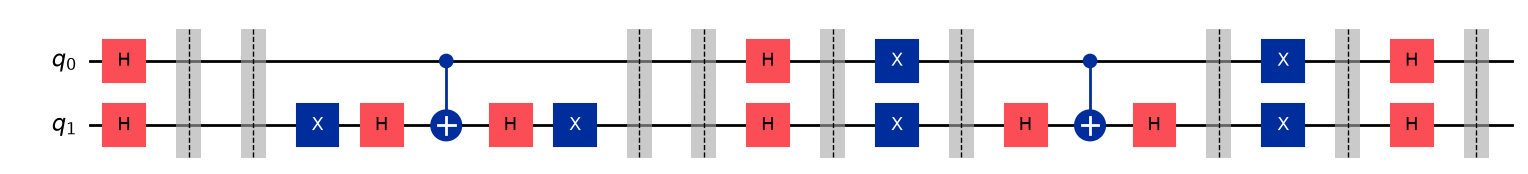

In [12]:
# Visualizar el circuito
grover_circuit.barrier()
grover_circuit.draw('mpl')

In [13]:
state = Statevector(grover_circuit)
print(state)
state.draw('latex')  # Vista visual de las amplitudes

Statevector([ 2.02038958e-17+0.j, -1.00000000e+00+0.j, -3.92523115e-17+0.j,
             -9.25962153e-17+0.j],
            dims=(2, 2))


<IPython.core.display.Latex object>

In [14]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Python Version: 3.13.14
UdeA-Medellin (2026) ©
